# Задача 4. Энергетический отклик детектора

В этой задаче мы исследуем, как полный собранный заряд зависит от энергии события и положения источника.
Мы ожидаем, что из-за квантовой природы света (распределение Пуассона) относительная ширина распределения будет уменьшаться с ростом энергии (как $1/\sqrt{E}$).
Также мы проверим, как смещение источника от центра влияет на средний собранный заряд из-за изменения телесных углов, под которыми видны ФЭУ.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Классы из предыдущей задачи ---
class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmt_coords = self._generate_pmt_coordinates()

    def _generate_pmt_coordinates(self):
        indices = np.arange(0, self.N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / self.N)
        theta = np.pi * (1 + 5**0.5) * indices
        x = self.R * np.cos(theta) * np.sin(phi)
        y = self.R * np.sin(theta) * np.sin(phi)
        z = self.R * np.cos(phi)
        return np.column_stack((x, y, z))

    def propagate_photons(self, origin, directions):
        b = np.dot(directions, origin)
        c = np.dot(origin, origin) - self.R**2
        discriminant = b**2 - c
        t = -b + np.sqrt(discriminant)
        hit_points = origin + t[:, np.newaxis] * directions
        distances = np.linalg.norm(hit_points[:, np.newaxis, :] - self.pmt_coords[np.newaxis, :, :], axis=2)
        hits = distances <= self.r
        return np.sum(hits, axis=0)

    def detect_photons(self, photons_per_pmt):
        return np.random.poisson(lam=photons_per_pmt * self.a)

class Source:
    def __init__(self, Y=10000.0):
        self.Y = Y

    def generate_photons(self, E):
        N_photons = int(E * self.Y)
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        cos_theta = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)
        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = cos_theta
        return np.column_stack((x, y, z))

# --- Вспомогательная функция для симуляции ---
def simulate_events(detector, source, E, N_events, origin):
    """Возвращает массив суммарных зарядов для N_events событий."""
    total_charges = []
    for _ in range(N_events):
        directions = source.generate_photons(E)
        photons_per_pmt = detector.propagate_photons(origin, directions)
        pes_per_pmt = detector.detect_photons(photons_per_pmt)
        total_charges.append(np.sum(pes_per_pmt))
    return np.array(total_charges)

### 1. Распределение для 1 МэВ в центре
Промоделируем 1000 событий с энергией 1 МэВ. Источник находится в начале координат `(0, 0, 0)`.

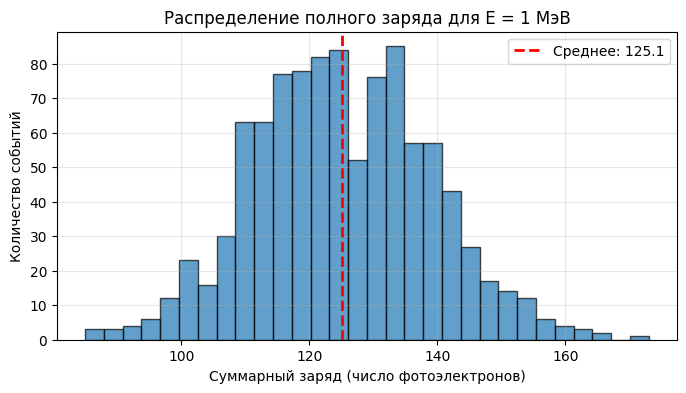

In [2]:
det = Detector()
src = Source()
origin_center = np.array([0.0, 0.0, 0.0])

# Симулируем 1000 событий для E = 1 МэВ
charges_1MeV = simulate_events(det, src, E=1.0, N_events=1000, origin=origin_center)

# Строим гистограмму
plt.figure(figsize=(8, 4))
plt.hist(charges_1MeV, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(np.mean(charges_1MeV), color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {np.mean(charges_1MeV):.1f}')
plt.title('Распределение полного заряда для E = 1 МэВ')
plt.xlabel('Суммарный заряд (число фотоэлектронов)')
plt.ylabel('Количество событий')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2. Зависимость относительной ширины от энергии
Посмотрим, как меняется относительная ширина распределения `std / mean` для разных энергий.
Ожидается, что она будет падать как $1/\sqrt{E}$, так как число фотонов растет линейно с энергией, а статистическая ошибка Пуассона растет как $\sqrt{N}$.

E = 0.2 МэВ | Среднее:  25.4 | Отн. ширина: 0.2372
E = 0.5 МэВ | Среднее:  62.3 | Отн. ширина: 0.1469
E = 0.7 МэВ | Среднее:  87.4 | Отн. ширина: 0.1359
E = 1.5 МэВ | Среднее: 188.4 | Отн. ширина: 0.0899
E = 2.0 МэВ | Среднее: 250.5 | Отн. ширина: 0.0744
E = 3.0 МэВ | Среднее: 375.2 | Отн. ширина: 0.0625


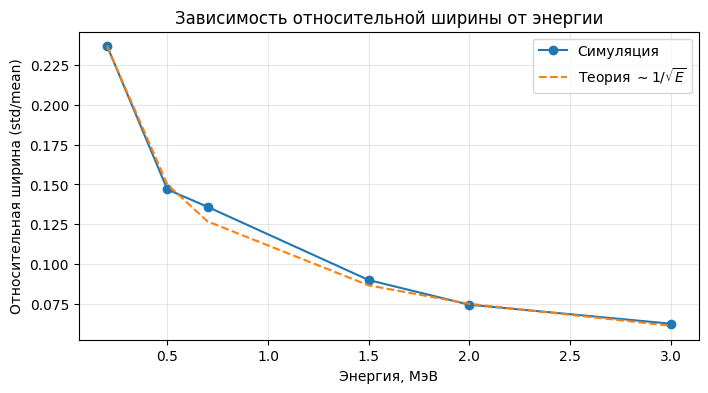

In [3]:
energies = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
rel_widths = []
means = []

# Для ускорения можно брать по 500 событий на каждую энергию
N_events = 500

for E in energies:
    charges = simulate_events(det, src, E, N_events, origin_center)
    mean_val = np.mean(charges)
    std_val = np.std(charges)
    rel_width = std_val / mean_val

    means.append(mean_val)
    rel_widths.append(rel_width)
    print(f"E = {E:>3} МэВ | Среднее: {mean_val:>5.1f} | Отн. ширина: {rel_width:.4f}")

# Строим график
plt.figure(figsize=(8, 4))
plt.plot(energies, rel_widths, 'o-', label='Симуляция')
# Нарисуем теоретическую кривую A/sqrt(E)
theory_curve = rel_widths[0] * np.sqrt(energies[0] / np.array(energies))
plt.plot(energies, theory_curve, '--', label=r'Теория $\sim 1/\sqrt{E}$')
plt.title('Зависимость относительной ширины от энергии')
plt.xlabel('Энергия, МэВ')
plt.ylabel('Относительная ширина (std/mean)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3. Смещение источника по оси z
Сдвинем источник на 1 метр вдоль оси z (координаты `[0, 0, 1]`). Радиус детектора 2 метра, поэтому источник останется внутри.
Сравним средний собранный заряд с центральным положением для энергии 1 МэВ.


Средний заряд (источник в центре): 125.14
Средний заряд (источник смещен на 1м): 125.39
Изменение среднего: 0.20%


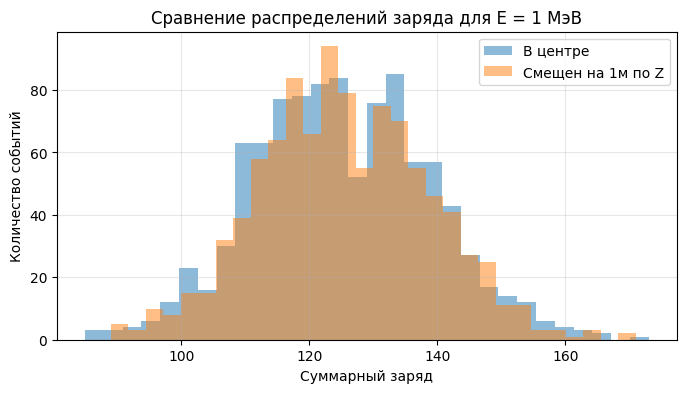

In [4]:
origin_shifted = np.array([0.0, 0.0, 1.0])

# Симулируем для смещенного источника
charges_shifted = simulate_events(det, src, E=1.0, N_events=1000, origin=origin_shifted)

mean_center = np.mean(charges_1MeV)
mean_shifted = np.mean(charges_shifted)

print(f"Средний заряд (источник в центре): {mean_center:.2f}")
print(f"Средний заряд (источник смещен на 1м): {mean_shifted:.2f}")
print(f"Изменение среднего: {(mean_shifted / mean_center - 1) * 100:.2f}%")

# Для наглядности наложим гистограммы друг на друга
plt.figure(figsize=(8, 4))
plt.hist(charges_1MeV, bins=30, alpha=0.5, label='В центре')
plt.hist(charges_shifted, bins=30, alpha=0.5, label='Смещен на 1м по Z')
plt.title('Сравнение распределений заряда для E = 1 МэВ')
plt.xlabel('Суммарный заряд')
plt.ylabel('Количество событий')
plt.legend()
plt.grid(alpha=0.3)
plt.show()